In [56]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import time
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import normalize

In [57]:
# DE1: Load both sheets and report row counts, column names, types, and missing values.
sheets = pd.read_excel("data/raw/online_retail_II.xlsx", sheet_name=None)
de1_reports = {}

for sheet_name, sheet_df in sheets.items():
    de1_reports[sheet_name] = pd.DataFrame({
        "dtype": sheet_df.dtypes.astype(str),
        "missing_values": sheet_df.isna().sum(),
    })
    print(f"{sheet_name}: {len(sheet_df):,} rows x {len(sheet_df.columns)} columns")
    print(f"Columns: {sheet_df.columns.tolist()}")
    print(de1_reports[sheet_name].to_string())
    print()

Year 2009-2010: 525,461 rows x 8 columns
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
                      dtype  missing_values
Invoice              object               0
StockCode            object               0
Description          object            2928
Quantity              int64               0
InvoiceDate  datetime64[us]               0
Price               float64               0
Customer ID         float64          107927
Country                 str               0

Year 2010-2011: 541,910 rows x 8 columns
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
                      dtype  missing_values
Invoice              object               0
StockCode            object               0
Description          object            1454
Quantity              int64               0
InvoiceDate  datetime64[us]               0
Price               float64        

In [58]:
df = pd.concat(sheets.values(), ignore_index=True)
print(f"Combined: {len(df):,} rows x {len(df.columns)} columns")

Combined: 1,067,371 rows x 8 columns


In [59]:
# DE2: Clean sequentially and log rows removed by each rule.
cleaning_log = []
print(f"Rows before cleaning: {len(df):,}")

cancellation_mask = df["Invoice"].astype("string").str.startswith("C", na=False)
removed = int(cancellation_mask.sum())
df = df.loc[~cancellation_mask].copy()
cleaning_log.append({"rule": "cancellations", "rows_removed": removed, "rows_remaining": len(df)})

non_positive_mask = (df["Quantity"] <= 0) | (df["Price"] <= 0)
removed = int(non_positive_mask.sum())
df = df.loc[~non_positive_mask].copy()
cleaning_log.append({"rule": "non-positive quantity or price", "rows_removed": removed, "rows_remaining": len(df)})

product_mask = (df["StockCode"].astype("string").str.isnumeric())
removed = int((~product_mask).sum())
df = df.loc[product_mask].copy()
cleaning_log.append({"rule": "non-product stock codes", "rows_removed": removed, "rows_remaining": len(df)})

no_customer_id_mask = df["Customer ID"].isna()
removed = int(no_customer_id_mask.sum())
df = df.loc[~no_customer_id_mask].copy()
cleaning_log.append({"rule": "missing customer ID", "rows_removed": removed, "rows_remaining": len(df)})

print(pd.DataFrame(cleaning_log).to_string(index=False))
print(f"Rows after cleaning: {len(df):,}")

Rows before cleaning: 1,067,371
                          rule  rows_removed  rows_remaining
                 cancellations         19494         1047877
non-positive quantity or price          6207         1041670
       non-product stock codes        129692          911978
           missing customer ID        197989          713989
Rows after cleaning: 713,989


In [65]:
# DE3: Use the final two months as test, then retain only customer-product
# purchases that do not appear in that customer's pre-test training history (R2).
latest_date = df["InvoiceDate"].max()

# Offset by two months to create test
test_start = latest_date - pd.DateOffset(months=2)
test_period_mask = df["InvoiceDate"] >= test_start

# Remove the test period from the training set
train = df.loc[~test_period_mask].copy()
# Copy the test period over to test_period
test_period = df.loc[test_period_mask].copy()

# Create pairs of (Customer ID, StockCode) for train and test_period
train_pairs = pd.MultiIndex.from_frame(train[["Customer ID", "StockCode"]].drop_duplicates())
test_pairs = pd.MultiIndex.from_frame(test_period[["Customer ID", "StockCode"]])

# Create a mask for test_period that identifies rows with novel customer-product pairs
novel_product_mask = ~test_pairs.isin(train_pairs)
# Create a new DataFrame for the held-out novel customer-product rows
test = test_period.loc[novel_product_mask].copy()
seen_product_rows_excluded = int((~novel_product_mask).sum())

print(f"Training rows: {len(train):,}")
print(f"Held-out novel customer-product rows: {len(test):,}")
print(f"Test customers: {test['Customer ID'].nunique():,}")

Training rows: 603,637
Held-out novel customer-product rows: 68,126
Test customers: 2,295


In [66]:
# DE4: sparse customer x product matrix from TRAINING rows only
# R1 choices: log1p of total units per customer-product; keep products bought by >=10 training customers.
min_customers_per_product = 10
product_customer_counts = train.groupby("StockCode")["Customer ID"].nunique()
selected_products = product_customer_counts[
    product_customer_counts >= min_customers_per_product
].index
matrix_train = train.loc[train["StockCode"].isin(selected_products)].copy()

customer_product_quantity = (
    matrix_train.groupby(["Customer ID", "StockCode"], sort=False)["Quantity"]
    .sum()
    .reset_index()
)
cust = {c: i for i, c in enumerate(customer_product_quantity["Customer ID"].unique())}
prod = {p: j for j, p in enumerate(customer_product_quantity["StockCode"].unique())}
rows = customer_product_quantity["Customer ID"].map(cust); cols = customer_product_quantity["StockCode"].map(prod)
vals = np.log1p(customer_product_quantity["Quantity"])
A = sp.csr_matrix((vals, (rows, cols)), shape=(len(cust), len(prod)))

print("Purchase value: log1p of total quantity per customer-product pair")
print(f"Product filter: at least {min_customers_per_product} distinct training customers")
print(f"Training transaction rows excluded by product filter: {len(train) - len(matrix_train):,}")
print(f"Products retained: {len(prod):,} of {len(product_customer_counts):,}")
print(A.shape, A.nnz, f"sparsity {1 - A.nnz / (A.shape[0] * A.shape[1]):.2%}")

Purchase value: log1p of total quantity per customer-product pair
Product filter: at least 10 distinct training customers
Training transaction rows excluded by product filter: 1,794
Products retained: 2,880 of 3,232
(5437, 2880) 367289 sparsity 97.65%


In [67]:
# Save the catalogue-wide training matrix, index maps, and full train/test splits.
processed_dir = Path("data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)
sp.save_npz(processed_dir / "train_customer_product.npz", A)
with (processed_dir / "index_maps.json").open("w", encoding="utf-8") as index_file:
    json.dump({
        "customer_id_to_row": {str(key): int(value) for key, value in cust.items()},
        "stock_code_to_col": {str(key): int(value) for key, value in prod.items()},
        "product_filter": {
            "minimum_distinct_training_customers": min_customers_per_product,
            "products_before_filter": int(len(product_customer_counts)),
            "products_retained": len(prod),
        },
        "purchase_value": "log1p(total Quantity per customer-product pair)",
    }, index_file, indent=2)
train.to_csv(processed_dir / "train.csv.gz", index=False, compression="gzip")
test.to_csv(processed_dir / "test.csv.gz", index=False, compression="gzip")
print(f"Saved matrix, maps, and full train/test splits under {processed_dir}")

Saved matrix, maps, and full train/test splits under data/processed


In [75]:
# DE5: Compare dense, sparse, and rank-50 factor storage.
n_customers, n_products = A.shape
bytes_per_value = A.dtype.itemsize

dense_bytes = n_customers * n_products * bytes_per_value
sparse_bytes = A.data.nbytes + A.indices.nbytes + A.indptr.nbytes
size_check_k = 200
factor_bytes = (n_customers + n_products) * size_check_k * bytes_per_value

matrix_report = {
    "shape": [int(n_customers), int(n_products)],
    "dtype": str(A.dtype),
    "dense_mib": dense_bytes / (1024 ** 2),
    "csr_mib": sparse_bytes / (1024 ** 2),
    "factor_rank_estimate": size_check_k,
    "factor_storage_mib_estimate": factor_bytes / (1024 ** 2),
}
with (processed_dir / "matrix_report.json").open("w", encoding="utf-8") as report_file:
    json.dump(matrix_report, report_file, indent=2)

print(f"Matrix: {n_customers:,} customers x {n_products:,} products ({A.dtype})")
print(f"Dense matrix: {matrix_report['dense_mib']:.2f} MiB")
print(f"CSR matrix: {matrix_report['csr_mib']:.2f} MiB")
print(
    f"Rank-{size_check_k} customer + product factors: "
    f"{matrix_report['factor_storage_mib_estimate']:.2f} MiB estimated"
)

Matrix: 5,437 customers x 2,880 products (float64)
Dense matrix: 119.47 MiB
CSR matrix: 4.22 MiB
Rank-200 customer + product factors: 12.69 MiB estimated


**ML Section**

ML1: Choose PCA or Truncated SVD and write a short justification, before running anything
ML1 justification: I'm choosing Truncated SVD because the customer-product matrix is sparse and Truncated SVD can handle sparse matrices efficiently.
Truncated SVD will operate on the matrix directly without having to center the data. 

In [68]:
# ML2: Compare TruncatedSVD relative Frobenius reconstruction error across k.

k_values = [10, 20, 50, 100, 200]

# Step 1: Compute ||A||_F
matrix_norm = np.sqrt(A.power(2).sum())
svd_results = []
svd_models = {}
pca_models = {}

for k in k_values:
    t = time.time()
    model = TruncatedSVD(n_components=k, random_state=42).fit(A)
    fit_seconds = time.time() - t

    # Step 2: Reconstruct A_k in row blocks to avoid making a full dense copy.
    A_k_rows = model.transform(A) @ model.components_
    A_k = sp.csr_matrix(A_k_rows)
    residual_squared = np.sqrt(((A - A_k).power(2)).sum())

    # Step 3: Divide ||A - A_k||_F by ||A||_F for relative reconstruction error.
    relative_frobenius_error = residual_squared / matrix_norm
    svd_results.append({
        "k": k,
        "relative_frobenius_error": relative_frobenius_error,
        "fit_seconds": fit_seconds,
    })
    svd_models[k] = model

# Step 4: Compare errors and fit times.
svd_results_df = pd.DataFrame(svd_results)
print(svd_results_df.to_string(index=False, formatters={
    "relative_frobenius_error": "{:.4f}".format,
    "fit_seconds": "{:.3f}".format,
}))

svd = svd_models[200]
P_vec = normalize(svd.components_.T)

  k relative_frobenius_error fit_seconds
 10                   0.8740       0.051
 20                   0.8428       0.091
 50                   0.7840       0.164
100                   0.7190       0.271
200                   0.6258       0.560


In [ ]:
# ML3: Find similar products and recommend products to a customer.
product_by_col = {column: product for product, column in prod.items()}

# Product factor vectors are normalized, so their dot product is cosine similarity.
def similar(j, n=10):
    s = P_vec @ P_vec[j]
    s[j] = -np.inf
    return np.argsort(-s)[:n]


# Find the 10 most similar products for every product.
similar_products = {}
for j in range(A.shape[1]):
    similar_products[product_by_col[j]] = [
        product_by_col[similar_j] for similar_j in similar(j)
    ]


def recommend_for_customer(customer_id, n=10):
    bought = A.getrow(cust[customer_id]).toarray().ravel()
    scores = np.zeros(bought.shape)
    #print(scores, bought)
    #print(scores.shape, bought.shape)
    # Add similarity to each product the customer bought, weighted by purchase value.
    for j in np.flatnonzero(bought):
        scores += bought[j] * (P_vec @ P_vec[j])

    scores /= bought.sum()
    scores[bought > 0] = -np.inf
    return np.argsort(-scores)[:n]

customer_id = next(iter(cust))
print(
    f"Products similar to {int(product_by_col[0])}:",
    [int(code) for code in similar_products[product_by_col[0]]],
)
print(
    f"Recommendations for customer {customer_id}:",
    [int(product_by_col[j]) for j in recommend_for_customer(customer_id)],
)

Products similar to 85048: [21821, 23085, 85045, 21743, 23112, 84352, 21143, 21763, 23111, 22599]
Recommendations for customer 13085.0: [22135, 22134, 22131, 22132, 22365, 22133, 21071, 21555, 22376, 22199]


In [72]:
#ML4 Evaluate on held-out purchases: hit rate at 10 for your model and for the best-seller baseline 
# (R3: Compare against the baseline of the 10 best sellers each customer has not bought.). Time the nightly job 
n_recommendations = 10

eligible_test = test.loc[test["Customer ID"].isin(cust) & test["StockCode"].isin(prod)].copy()
heldout_by_customer = (eligible_test.groupby("Customer ID")["StockCode"].agg(lambda codes: {prod[code] for code in codes}))


print(f"Held-out purchases for {len(heldout_by_customer):,} customers in the test set "
      f"({len(eligible_test):,} rows of {len(test):,} total novel customer-product rows)")

popular_sales = (
    train.loc[train["StockCode"].isin(prod)]
    .groupby("StockCode")["Quantity"].sum()
    .sort_values(ascending=False)
)


description_by_stockcode = (
    train.dropna(subset=["Description"]).drop_duplicates("StockCode").set_index("StockCode")["Description"])

top_sellers = pd.DataFrame({
    "StockCode":  popular_sales.index[:n_recommendations],
    "Description": [description_by_stockcode.get(code, "Description unavailable") for code in popular_sales.index[:n_recommendations]],
    "Training quantity": popular_sales.iloc[:n_recommendations].to_numpy()})

print("Top 10 best-selling products:")
print(top_sellers.to_string(index=False))

best_seller_scores = np.zeros(A.shape[1], dtype=np.float64)
best_seller_cols = popular_sales.index.map(prod.get)
best_seller_scores[best_seller_cols] = popular_sales
model_hits = []
baseline_hits = []

for customer_id, heldout_products in heldout_by_customer.items():
    bought = A.getrow(cust[customer_id]).toarray().ravel()

    # Score products from this customer's training purchases using the SVD factors.
    scores = P_vec @ (P_vec.T @ bought)
    scores[bought > 0] = -np.inf
    model_top10 = set(np.argsort(-scores)[:n_recommendations])

    # Recommend the best sellers this customer has not already bought.
    baseline_customer_scores = best_seller_scores.copy()
    baseline_customer_scores[bought > 0] = -np.inf
    baseline_top10 = set(np.argsort(-baseline_customer_scores)[:n_recommendations])

    model_hits.append(bool(model_top10 & heldout_products))
    baseline_hits.append(bool(baseline_top10 & heldout_products))

print(f"Customers evaluated: {len(heldout_by_customer):,}")
print(f"Model hit rate@{n_recommendations}: {np.mean(model_hits):.4f}")
print(f"Best-seller hit rate@{n_recommendations}: {np.mean(baseline_hits):.4f}")

Held-out purchases for 1,898 customers in the test set (48,026 rows of 68,126 total novel customer-product rows)
Top 10 best-selling products:
 StockCode                        Description  Training quantity
     84077  WORLD WAR 2 GLIDERS ASSTD DESIGNS              96169
     21212   PACK OF 72 RETRO SPOT CAKE CASES              87086
     23166     MEDIUM CERAMIC TOP STORAGE JAR              76902
     84879      ASSORTED COLOUR BIRD ORNAMENT              71391
     17003                BROCADE RING PURSE               67773
     22197            POPCORN HOLDER , SMALL               59307
     21977 PACK OF 60 PINK PAISLEY CAKE CASES              53125
     84991        60 TEATIME FAIRY CAKE CASES              50607
     15036          ASSORTED COLOURS SILK FAN              39974
     22492            MINI PAINT SET VINTAGE               39259
Customers evaluated: 1,898
Model hit rate@10: 0.2329
Best-seller hit rate@10: 0.1465


In [71]:
# ML5: Fit PCA to the same matrix as TruncatedSVD, using k=200.
pca_k = 200
t = time.perf_counter()
pca = PCA(n_components=pca_k, svd_solver="arpack", random_state=42).fit(A)
pca_fit_seconds = time.perf_counter() - t

pca_reconstructed = sp.csr_matrix(pca.transform(A) @ pca.components_)
pca_relative_error = np.sqrt(((A - pca_reconstructed).power(2)).sum()) / matrix_norm
print(f"PCA k={pca_k} fit time: {pca_fit_seconds:.3f} seconds")
print(f"PCA relative Frobenius reconstruction error: {pca_relative_error:.4f}")
print(f"PCA variance explained at k={pca_k}: {pca.explained_variance_ratio_.sum():.4f}")

# Evaluate PCA recommendations using the same held-out set and scoring rule as ML4.
pca_product_vectors = normalize(pca.components_.T)
pca_model_hits = []
pca_baseline_hits = []
for customer_id, heldout_products in heldout_by_customer.items():
    bought = A.getrow(cust[customer_id]).toarray().ravel()
    
    scores = pca_product_vectors @ (pca_product_vectors.T @ bought)
    scores[bought > 0] = -np.inf
    model_top10 = set(np.argsort(-scores)[:n_recommendations])
    
    baseline_customer_scores = best_seller_scores.copy()
    baseline_customer_scores[bought > 0] = -np.inf
    baseline_top10 = set(np.argsort(-baseline_customer_scores)[:n_recommendations])
    
    pca_model_hits.append(bool(model_top10 & heldout_products))
    pca_baseline_hits.append(bool(baseline_top10 & heldout_products))

pca_hit_rate = np.mean(pca_model_hits)
pca_baseline_hit_rate = np.mean(pca_baseline_hits)
print(f"PCA hit rate@{n_recommendations}: {pca_hit_rate:.4f}")
print(f"Best-seller baseline hit rate@{n_recommendations}: {pca_baseline_hit_rate:.4f}")

PCA k=200 fit time: 1.464 seconds
PCA relative Frobenius reconstruction error: 0.6581
PCA variance explained at k=200: 0.5928
PCA hit rate@10: 0.2345
Best-seller baseline hit rate@10: 0.1465


In [79]:
# Score top-10 recommendations for every customer represented in the training matrix.
job_start = time.perf_counter()
recommendations_by_customer = {}

for customer_id, customer_row in cust.items():
    bought = A.getrow(customer_row).toarray().ravel()

    scores = P_vec @ (P_vec.T @ bought)
    scores[bought > 0] = -np.inf
    recommended_columns = np.argsort(-scores)[:n_recommendations]
    recommendations_by_customer[customer_id] = [
        int(product_by_col[column]) for column in recommended_columns
    ]

full_table_job_seconds = time.perf_counter() - job_start
print(f"Customers scored: {len(recommendations_by_customer):,}")
print(f"Recommendations per customer: {n_recommendations}")
print(f"Full-table recommendation scoring time: {full_table_job_seconds:.3f} seconds")

Customers scored: 5,437
Recommendations per customer: 10
Full-table recommendation scoring time: 0.961 seconds


## Comparison Table (ML5)

| Measure | PCA | Truncated SVD |
|---|---|---|
| k used | 200 | 200 |
| Fit time (seconds) | 1.577 | 0.515 |
| Peak additional RSS during fit (MB) | 4.62 | 0.00 |
| Size of stored product factors (MB) | 4.22 | 4.22 |
| Relative Frobenius reconstruction error | 0.6581 | 0.6258 |
| Hit rate at 10 on held-out purchases | 0.2345 | 0.2292 |
| Best-seller baseline hit rate at 10 | 0.1465 | 0.1465 |
| What component 1 represents, in words | Main direction of variation around the average customer, so high scores indicate above-average purchases | Often "overall volume", how much a customer buys so, high scores emphasize purchases of the same products. |


=== Occasional gift and decor shoppers (cluster 0) ===
Customers: 3976
Top countries:
  - United Kingdom: 3699
  - France: 48
  - Germany: 47
  - Spain: 25
  - Netherlands: 17
Top products:
  - 84879 | ASSORTED COLOUR BIRD ORNAMENT | mean log-qty: 0.338
  - 22423 | REGENCY CAKESTAND 3 TIER | mean log-qty: 0.223
  - 84946 | ANTIQUE SILVER TEA GLASS ETCHED | mean log-qty: 0.216
  - 21212 | PACK OF 72 RETRO SPOT CAKE CASES | mean log-qty: 0.215
  - 22469 | HEART OF WICKER SMALL | mean log-qty: 0.214
  - 21232 | STRAWBERRY CERAMIC TRINKET BOX | mean log-qty: 0.211
  - 22457 | NATURAL SLATE HEART CHALKBOARD  | mean log-qty: 0.200
  - 47566 | PARTY BUNTING | mean log-qty: 0.196
  - 22178 | VICTORIAN GLASS HANGING T-LIGHT | mean log-qty: 0.186
  - 22138 | BAKING SET 9 PIECE RETROSPOT  | mean log-qty: 0.181

=== Frequent retro lunch and baking buyers (cluster 1) ===
Customers: 251
Top countries:
  - United Kingdom: 207
  - Germany: 17
  - France: 12
  - Switzerland: 3
  - Portugal: 2
Top prod

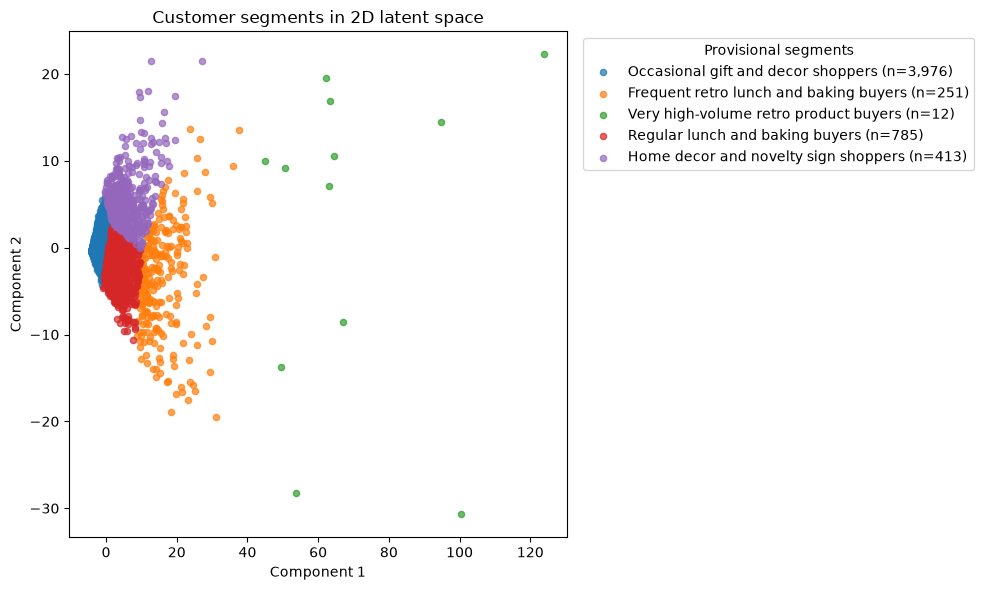

In [77]:
#ML6 Customer map: project customers on 2 components, cluster into 3 to 6 groups
#(for example k-means), describe each group with its top products and countries

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Use the same 2D latent embedding for all customers in the training matrix.
pca_2d = PCA(n_components=2, random_state=42)
customer_emb = pca_2d.fit_transform(A.toarray())

# Keep one metadata row per customer so labels align with embedding rows.
customer_meta = (
    df.loc[:, ["Customer ID", "Country"]]
      .dropna(subset=["Customer ID"])
      .copy()
)
customer_meta["Customer ID"] = customer_meta["Customer ID"].astype(int)
customer_meta = customer_meta.drop_duplicates("Customer ID").copy()
customer_meta["row"] = customer_meta["Customer ID"].map(cust)
customer_meta = customer_meta.dropna(subset=["row"]).copy()
customer_meta["row"] = customer_meta["row"].astype(int)
customer_meta = customer_meta[customer_meta["row"].isin(range(A.shape[0]))].copy()

# K-means on all customer coordinates; use row indices to align labels with metadata.
n_clusters = 5
km = KMeans(n_clusters=n_clusters, random_state=42, n_init=20)
cluster_labels = km.fit_predict(customer_emb)
customer_meta["cluster"] = cluster_labels[customer_meta["row"].to_numpy()]

# Provisional names summarize each cluster's dominant products and purchase intensity.
cluster_names = {
    0: "Occasional gift and decor shoppers",
    1: "Frequent retro lunch and baking buyers",
    2: "Very high-volume retro product buyers",
    3: "Regular lunch and baking buyers",
    4: "Home decor and novelty sign shoppers",
}

# Top product descriptions
description_by_stockcode = (
    train.dropna(subset=["Description"])
    .drop_duplicates("StockCode")
    .set_index("StockCode")["Description"]
)
stockcode_by_col = {col: code for code, col in prod.items()}

# Helper to get products with highest average purchase score in a cluster
def cluster_top_products(cluster_id, n=10):
    rows = customer_meta.loc[customer_meta["cluster"] == cluster_id, "row"].to_numpy()
    if len(rows) == 0:
        return []
    cluster_matrix = A[rows].toarray()
    mean_scores = cluster_matrix.mean(axis=0)
    top_cols = np.argsort(mean_scores)[::-1][:n]
    return [
        {
            "StockCode": int(stockcode_by_col[j]),
            "Description": description_by_stockcode.get(int(stockcode_by_col[j]), "Description unavailable"),
            "Mean_log_qty": float(mean_scores[j]),
        }
        for j in top_cols
    ]

# Helper to summarize countries
def cluster_top_countries(cluster_id, n=5):
    country_counts = (
        customer_meta.loc[customer_meta["cluster"] == cluster_id, "Country"]
        .fillna("Unknown")
        .value_counts()
        .head(n)
    )
    return [{"Country": country, "Customers": int(count)} for country, count in country_counts.items()]

# Print cluster summaries
for cid, cluster_name in cluster_names.items():
    print(f"\n=== {cluster_name} (cluster {cid}) ===")
    print(f"Customers: {int((customer_meta['cluster'] == cid).sum())}")
    print("Top countries:")
    for item in cluster_top_countries(cid):
        print(f"  - {item['Country']}: {item['Customers']}")
    print("Top products:")
    for item in cluster_top_products(cid):
        print(
            f"  - {item['StockCode']} | {item['Description']} | "
            f"mean log-qty: {item['Mean_log_qty']:.3f}"
        )

# 2D scatter plot with descriptive segment labels
fig, ax = plt.subplots(figsize=(10, 6))
cluster_cmap = plt.get_cmap("tab10")
for cid, cluster_name in cluster_names.items():
    cluster_mask = cluster_labels == cid
    ax.scatter(
        customer_emb[cluster_mask, 0],
        customer_emb[cluster_mask, 1],
        color=cluster_cmap(cid),
        label=f"{cluster_name} (n={int(cluster_mask.sum()):,})",
        s=20,
        alpha=0.7,
    )
ax.set_title("Customer segments in 2D latent space")
ax.set_xlabel("Component 1")
ax.set_ylabel("Component 2")
ax.legend(title="Provisional segments", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()